<a href="https://colab.research.google.com/github/charlieswan7/Data-Acquisition-Project/blob/main/Data_Acquisition_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data Acquisition Project: Irish House Prices**

Research Question: How have house prices changed across counties in Ireland and have they risen faster than disposable income per person?

**Kaggle Dataset:** Irish Property price register - https://www.kaggle.com/datasets/fionnhughes/property-price-register

The project aims to investigate changes in house prices across Ireland for the years 2012 to 2021. The Kaggle dataset (Irish property price register) will be combined with disposable income statistics from the Central Statistics Office (CSO) website to help examine how house prices and incomes have changed across Irish counties between 2012 and 2021.

# Upload and import CSV


In [2]:
import pandas as pd

df = pd.read_csv("property_price_register.csv")

df.head()


/tmp/ipykernel_1045/4239949234.py:3: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("property_price_register.csv")


,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN


# Examining the dataset



In [3]:
df.shape

(807936, 9)

In [4]:
df.columns

Index(['date_of_sale', 'address', 'county', 'eircode', 'price_eur',
       'not_full_market_price', 'vat_exclusive', 'description',
       'property_size'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 807936 entries, 0 to 807935
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date_of_sale           807936 non-null  object 
 1   address                807936 non-null  object 
 2   county                 807936 non-null  object 
 3   eircode                251432 non-null  object 
 4   price_eur              807936 non-null  float64
 5   not_full_market_price  807936 non-null  bool   
 6   vat_exclusive          807936 non-null  bool   
 7   description            807936 non-null  object 
 8   property_size          52608 non-null   object 
dtypes: bool(2), float64(1), object(6)
memory usage: 44.7+ MB


In [6]:
df.head(10)

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
5,2010-01-04,"90 Suncroft Drive, Tallaght, Dublin 24",Dublin,NaN,147950.0,False,False,Second-Hand Dwelling house /Apartment,NaN
6,2010-01-04,"Ballyeden, Ballyoughter, Gorey",Wexford,NaN,255022.0,False,True,New Dwelling house /Apartment,greater than 125 sq metres
7,2010-01-04,"CARROWTRASNA, CARROWMORE LACKEN, BALLINA",Mayo,NaN,245000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
8,2010-01-04,"Cloonlaughnan, Mount Talbot",Roscommon,NaN,145000.0,False,True,New Dwelling house /Apartment,greater than 125 sq metres
9,2010-01-04,"Killult, Falcarragh",Donegal,NaN,215000.0,False,True,New Dwelling house /Apartment,greater than 125 sq metres


In [7]:
df.describe()

,price_eur
count,8.079360e+05
mean,3.221694e+05
std,1.317879e+06
min,5.001000e+03
25%,1.450000e+05
50%,2.450000e+05
75%,3.670000e+05
max,3.876652e+08


# Exploring the data values

In [11]:
df["county"].unique()

array(['Dublin', 'Laois', 'Tipperary', 'Wicklow', 'Cork', 'Wexford',
       'Mayo', 'Roscommon', 'Donegal', 'Longford', 'Limerick', 'Galway',
       'Cavan', 'Meath', 'Carlow', 'Clare', 'Kilkenny', 'Sligo',
       'Waterford', 'Offaly', 'Kildare', 'Louth', 'Kerry', 'Westmeath',
       'Monaghan', 'Leitrim'], dtype=object)

In [12]:
df["county"].value_counts()

,count
county,
Dublin,253128
Cork,89418
Kildare,44108
Galway,38940
Meath,33593
Limerick,29601
Wexford,28232
Wicklow,27316
Louth,22754


In [13]:
df["description"].value_counts()

,count
description,
Second-Hand Dwelling house /Apartment,663246
New Dwelling house /Apartment,144641
Teach/Árasán Cónaithe Atháimhe,45
Teach/Árasán Cónaithe Nua,3
Teach/?ras?n C?naithe Nua,1


In [14]:
df["price_eur"].describe()

,price_eur
count,8.079360e+05
mean,3.221694e+05
std,1.317879e+06
min,5.001000e+03
25%,1.450000e+05
50%,2.450000e+05
75%,3.670000e+05
max,3.876652e+08


In [15]:
df["not_full_market_price"].value_counts()

,count
not_full_market_price,
False,766965
True,40971


In [16]:
df["vat_exclusive"].value_counts()

,count
vat_exclusive,
False,665664
True,142272


# Selecting 2012-2021

In [20]:
df["date_of_sale"] = pd.to_datetime(df["date_of_sale"])

df_filtered = df[df["date_of_sale"].dt.year.between(2012, 2021)]

In [23]:
df_filtered["date_of_sale"].dt.year.value_counts().sort_index()

,count
date_of_sale,
2012,25345
2013,30064
2014,43642
2015,49106
2016,49860
2017,54948
2018,57396
2019,59009
2020,49493


In [25]:
df_filtered["county"].nunique()

26

In [26]:
df_filtered.shape

(478440, 9)

# Creating a sample dataset with less data

In [28]:
df_sample = df_filtered.sample(n=10000, random_state=42).reset_index(drop=True)

In [31]:
df_sample["date_of_sale"].dt.year.value_counts().sort_index()

,count
date_of_sale,
2012,524
2013,647
2014,922
2015,1056
2016,1006
2017,1171
2018,1241
2019,1184
2020,979


In [34]:
df_sample["county"].value_counts()

,count
county,
Dublin,3111
Cork,1068
Kildare,500
Galway,493
Meath,441
Wexford,367
Limerick,355
Wicklow,343
Donegal,286


In [36]:
df_sample.head(10)

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2021-11-26,"84 CEDAR PLACE, RIDGEWOOD, SWORDS",Dublin,K67KH57,275000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2021-04-27,"APT 7, MILLRACE VIEW, WOLFE TONE ST",Sligo,NaN,125000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
2,2021-04-28,"2 CLEGGAN RD, BALLYFERMOT, DUBLIN 10",Dublin,D10RX93,270000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2021-08-31,"6 GRATTAN COURT, GRATTAN ST, DUBLIN 2",Dublin,D02FE84,400000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2014-12-18,"220 COILL TIRE, AN FIODAN, DOUGHISKA GALWAY",Galway,NaN,97500.0,False,False,Second-Hand Dwelling house /Apartment,NaN
5,2020-10-08,"3 CANAL DR, PROSPECT WOOD, LONGFORD",Longford,NaN,85000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
6,2017-07-25,"48 THE ORCHARD, CASTLETROY, LIMERICK",Limerick,NaN,144000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
7,2018-04-16,"29 LIOSCARRIG DR, CAHERSLEE TRALEE, KERRY",Kerry,NaN,170000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
8,2019-04-12,"6 THE CEDARS, BRIDEWOOD, OVENS",Cork,NaN,280000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
9,2015-10-08,"382 Malahide Marina, Malahide",Dublin,NaN,300000.0,False,False,Second-Hand Dwelling house /Apartment,NaN


**Kaggle Dataset description**

The dataset I chose was the Irish property price register sales from kaggle. It has 807,936 house sales across the 26 counties in Ireland for the years 2010-2026. It includes data on date of sale, county, property price, address, property description, eircode,	not_full_market_price, vat_exclusive and	property_size.

I examined the dataset using pandas to check the number of rows, columns, data types and different values in the dataset.

I then filtered the data to get rid of the 2010, 2011, and 2022-2026 years. This left me with still over 400,000 rows. The reason I chose these years was because they match the years in the CSO income data that I will be scraping.

As the dataset was still very large, i decided to take a random sample of 10000 rows. This sample includes sales from all 26 counties and all 10 years.

I will use the data to compare how house prices have changed across different counties and whether it has increased quicker than disposable income per person.

# Web Scraping

For the second part of my project, I will be scraping two tables from the CSO website. This is to get data on disposable income for Irish counties between 2012 and 2021. The two tables I chose are Estimates of disposable income per person by region and county, 2012 to 2021 (5.3) and Estimates of disposable income per person (excluding rent) by region and county, 2012 to 2021 (5.7).

In [38]:
import urllib.request
from bs4 import BeautifulSoup

In [39]:
url = "https://www.cso.ie/en/releasesandpublications/ep/p-cirgdp/countyincomesandregionalgdp2021/data/"

response = urllib.request.urlopen(url)
raw_html = response.read().decode("utf-8")

soup = BeautifulSoup(raw_html, "html.parser")


In [40]:
tables = soup.find_all("table")
len(tables)

22

In [51]:
# Table 5.3
table_53 = tables[3]
# Table 5.7
table_57 = tables[7]
print(table_53.get_text(" ", strip=True)[:200])
print(table_57.get_text(" ", strip=True)[:200])


Table 5.3   Estimates of Disposable Income Per Person by Region and County, 2012 to 2021 1, 2 Disposable Income per Person (€) 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 1, 2 Northern & Western
Table 5.7   Estimates of Disposable Income Per Person (Excluding Rent) by Region and County, 2012 to 2021 1,2,3 Disposable Income Per Person (€)  (Excluding Rent) 2012 2013 2014 2015 2016 2017 2018 20


In [56]:
rows = table_53.find_all("tr")
data_53 = []
for row in rows:
    cells = row.find_all(["th", "td"])
    values = []

    for cell in cells:
        values.append(cell.get_text(strip=True))

    data_53.append(values)
df_income53 = pd.DataFrame(data_53)
df_income53.head(10)

,0,1,2,3,4,5,6,7,8,9,10
0,Table 5.3 Estimates of Disposable Income Per...,None,None,None,None,None,None,None,None,None,None
1,,Disposable Income per Person (€),None,None,None,None,None,None,None,None,None
2,,2012,2013,2014,2015,2016,2017,2018,2019,2020,"20211, 2"
3,Northern & Western,"16,266","16,219","16,308","16,892","17,288","17,992","18,562","19,819","20,958","21,596"
4,,,,,,,,,,,
5,Border,"15,522","15,383","15,454","16,074","16,453","17,111","17,609","18,860","20,008","20,445"
6,Cavan,"15,676","16,174","16,171","16,900","17,552","18,148","18,543","19,167","20,397","21,097"
7,Donegal,"14,791","14,287","14,369","15,019","15,255","15,876","16,424","17,746","18,984","19,253"
8,Leitrim,"16,455","16,755","17,000","17,234","17,621","18,165","18,800","19,859","21,029","21,169"
9,Monaghan,"15,727","15,801","15,838","16,514","16,981","17,886","18,416","19,724","20,716","21,516"


In [55]:
rows = table_57.find_all("tr")
data_57 = []

for row in rows:
    cells = row.find_all(["th", "td"])
    values = []

    for cell in cells:
        values.append(cell.get_text(strip=True))
    data_57.append(values)
df_income57 = pd.DataFrame(data_57)
df_income57.head(10)


,0,1,2,3,4,5,6,7,8,9,10
0,Table 5.7 Estimates of Disposable Income Per...,None,None,None,None,None,None,None,None,None,None
1,,Disposable Income Per Person (€) (Excluding R...,None,None,None,None,None,None,None,None,None
2,,2012,2013,2014,2015,2016,2017,2018,2019,2020,"20211,2,3"
3,Northern & Western,"15,225","15,156","15,163","15,619","16,120","16,724","17,154","18,262","19,280","19,986"
4,,,,,,,,,,,
5,Border,"14,605","14,446","14,445","14,950","15,450","16,023","16,399","17,513","18,557","19,316"
6,Cavan,"14,779","15,259","15,182","15,797","16,573","17,087","17,364","17,898","19,030","19,891"
7,Donegal,"13,916","13,392","13,405","13,947","14,317","14,858","15,295","16,464","17,604","18,309"
8,Leitrim,"15,541","15,822","15,994","16,113","16,601","17,057","17,567","18,485","19,546","20,077"
9,Monaghan,"14,827","14,881","14,848","15,412","15,966","16,784","17,191","18,372","19,258","20,413"


In [57]:
counties = ["Carlow", "Cavan", "Clare", "Cork", "Donegal", "Dublin", "Galway", "Kerry", "Kildare", "Kilkenny", "Laois", "Leitrim", "Limerick", "Longford", "Louth", "Mayo", "Meath", "Monaghan", "Offaly", "Roscommon", "Sligo", "Tipperary", "Waterford", "Westmeath", "Wexford", "Wicklow"]

In [58]:
df_income53 = df_income53[df_income53[0].isin(counties)]
df_income57 = df_income57[df_income57[0].isin(counties)]

In [59]:
columns = ["County", 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]
df_income53.columns = columns
df_income57.columns = columns

df_income53 = df_income53.reset_index(drop=True)
df_income57 = df_income57.reset_index(drop=True)

In [60]:
for year in range(2012, 2022):
    df_income53[year] = pd.to_numeric(df_income53[year].str.replace(",", ""))
    df_income57[year] = pd.to_numeric(df_income57[year].str.replace(",", ""))

In [61]:
df_income53

,County,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Cavan,15676,16174,16171,16900,17552,18148,18543,19167,20397,21097
1,Donegal,14791,14287,14369,15019,15255,15876,16424,17746,18984,19253
2,Leitrim,16455,16755,17000,17234,17621,18165,18800,19859,21029,21169
3,Monaghan,15727,15801,15838,16514,16981,17886,18416,19724,20716,21516
4,Sligo,16508,16144,16221,16776,17119,17769,18155,19912,20882,21207
5,Galway,17268,17155,17213,17971,18529,19328,20061,21221,22317,23495
6,Mayo,16882,17122,17165,17468,17681,18430,18957,20296,21522,21848
7,Roscommon,15646,15826,16242,16501,16739,17259,17726,19086,20160,20477
8,Dublin,19942,19303,19304,20314,21457,22895,23617,24425,25949,27958
9,Kildare,18204,18245,18444,19633,20406,21544,22029,22505,23836,24299


In [62]:
df_income57

,County,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Cavan,14779,15259,15182,15797,16573,17087,17364,17898,19030,19891
1,Donegal,13916,13392,13405,13947,14317,14858,15295,16464,17604,18309
2,Leitrim,15541,15822,15994,16113,16601,17057,17567,18485,19546,20077
3,Monaghan,14827,14881,14848,15412,15966,16784,17191,18372,19258,20413
4,Sligo,15447,15060,15055,15482,15946,16497,16743,18331,19179,19676
5,Galway,16013,15877,15835,16440,17030,17701,18252,19257,20200,20858
6,Mayo,15848,16066,16027,16202,16586,17243,17642,18824,19939,20592
7,Roscommon,14668,14829,15168,15307,15705,16137,16479,17699,18666,19353
8,Dublin,18246,17581,17448,18254,19096,20324,20752,21381,22660,23279
9,Kildare,16923,16936,17033,18060,18719,19704,19973,20317,21466,22198


In [64]:
df_income53.shape

(26, 11)

In [63]:
df_income57.shape

(26, 11)

In [65]:
df_income53.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   County  26 non-null     object
 1   2012    26 non-null     int64 
 2   2013    26 non-null     int64 
 3   2014    26 non-null     int64 
 4   2015    26 non-null     int64 
 5   2016    26 non-null     int64 
 6   2017    26 non-null     int64 
 7   2018    26 non-null     int64 
 8   2019    26 non-null     int64 
 9   2020    26 non-null     int64 
 10  2021    26 non-null     int64 
dtypes: int64(10), object(1)
memory usage: 2.4+ KB


In [66]:
df_income57.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   County  26 non-null     object
 1   2012    26 non-null     int64 
 2   2013    26 non-null     int64 
 3   2014    26 non-null     int64 
 4   2015    26 non-null     int64 
 5   2016    26 non-null     int64 
 6   2017    26 non-null     int64 
 7   2018    26 non-null     int64 
 8   2019    26 non-null     int64 
 9   2020    26 non-null     int64 
 10  2021    26 non-null     int64 
dtypes: int64(10), object(1)
memory usage: 2.4+ KB


## CSO Dataset description
For the second dataset I scraped two tables from the Central statistics office (CSO) website using BeautifulSoup. Table 5.3 has data on disposable income per person by county, Table 5.7 has data on disposable income per person excluding rent.

I extracted the data from the tables and stored it into two pandas dataframes. After that i removed the regional totals as the first dataset has no data for regionals. This data provides new information that isnt in the kaggle dataset. I will merge them using county and year.

# Merging the datasets
In this section, I will merge the two CSO tables with the kaggle house sales dataset. They will be joined using county and year, so that each property sale can be matched with the disposable income per person for that year and that county.

In [82]:
df_merged["Year"] = df_merged["Year"].astype(int)

In [83]:
income53 = pd.melt(
    df_income53,
    id_vars="County",
    var_name="Year",
    value_name="Disposable_Income")
income53.head(10)

,County,Year,Disposable_Income
0,Cavan,2012,15676
1,Donegal,2012,14791
2,Leitrim,2012,16455
3,Monaghan,2012,15727
4,Sligo,2012,16508
5,Galway,2012,17268
6,Mayo,2012,16882
7,Roscommon,2012,15646
8,Dublin,2012,19942
9,Kildare,2012,18204


In [68]:
income57 = pd.melt(
    df_income57,
    id_vars="County",
    var_name="Year",
    value_name="Income_Excluding_Rent")
income57.head(10)

,County,Year,Income_Excluding_Rent
0,Cavan,2012,14779
1,Donegal,2012,13916
2,Leitrim,2012,15541
3,Monaghan,2012,14827
4,Sligo,2012,15447
5,Galway,2012,16013
6,Mayo,2012,15848
7,Roscommon,2012,14668
8,Dublin,2012,18246
9,Kildare,2012,16923


In [69]:
df_income = pd.merge(
    income53,
    income57,
    on=["County", "Year"])
df_income.head(10)

,County,Year,Disposable_Income,Income_Excluding_Rent
0,Cavan,2012,15676,14779
1,Donegal,2012,14791,13916
2,Leitrim,2012,16455,15541
3,Monaghan,2012,15727,14827
4,Sligo,2012,16508,15447
5,Galway,2012,17268,16013
6,Mayo,2012,16882,15848
7,Roscommon,2012,15646,14668
8,Dublin,2012,19942,18246
9,Kildare,2012,18204,16923


In [70]:
df_income.shape

(260, 4)

In [71]:
df_sample["Year"] = df_sample["date_of_sale"].dt.year
df_sample.head()

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size,Year
0,2021-11-26,"84 CEDAR PLACE, RIDGEWOOD, SWORDS",Dublin,K67KH57,275000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
1,2021-04-27,"APT 7, MILLRACE VIEW, WOLFE TONE ST",Sligo,NaN,125000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
2,2021-04-28,"2 CLEGGAN RD, BALLYFERMOT, DUBLIN 10",Dublin,D10RX93,270000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
3,2021-08-31,"6 GRATTAN COURT, GRATTAN ST, DUBLIN 2",Dublin,D02FE84,400000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
4,2014-12-18,"220 COILL TIRE, AN FIODAN, DOUGHISKA GALWAY",Galway,NaN,97500.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2014


In [72]:
df_sample = df_sample.rename(columns={"county": "County"})
df_sample.head()

,date_of_sale,address,County,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size,Year
0,2021-11-26,"84 CEDAR PLACE, RIDGEWOOD, SWORDS",Dublin,K67KH57,275000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
1,2021-04-27,"APT 7, MILLRACE VIEW, WOLFE TONE ST",Sligo,NaN,125000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
2,2021-04-28,"2 CLEGGAN RD, BALLYFERMOT, DUBLIN 10",Dublin,D10RX93,270000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
3,2021-08-31,"6 GRATTAN COURT, GRATTAN ST, DUBLIN 2",Dublin,D02FE84,400000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021
4,2014-12-18,"220 COILL TIRE, AN FIODAN, DOUGHISKA GALWAY",Galway,NaN,97500.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2014


In [73]:
df_merged = pd.merge(
    df_sample,
    df_income,
    on=["County", "Year"],
    how="left")
df_merged.head(10)

,date_of_sale,address,County,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size,Year,Disposable_Income,Income_Excluding_Rent
0,2021-11-26,"84 CEDAR PLACE, RIDGEWOOD, SWORDS",Dublin,K67KH57,275000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
1,2021-04-27,"APT 7, MILLRACE VIEW, WOLFE TONE ST",Sligo,NaN,125000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,21207,19676
2,2021-04-28,"2 CLEGGAN RD, BALLYFERMOT, DUBLIN 10",Dublin,D10RX93,270000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
3,2021-08-31,"6 GRATTAN COURT, GRATTAN ST, DUBLIN 2",Dublin,D02FE84,400000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
4,2014-12-18,"220 COILL TIRE, AN FIODAN, DOUGHISKA GALWAY",Galway,NaN,97500.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2014,17213,15835
5,2020-10-08,"3 CANAL DR, PROSPECT WOOD, LONGFORD",Longford,NaN,85000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2020,21847,20546
6,2017-07-25,"48 THE ORCHARD, CASTLETROY, LIMERICK",Limerick,NaN,144000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2017,20647,19212
7,2018-04-16,"29 LIOSCARRIG DR, CAHERSLEE TRALEE, KERRY",Kerry,NaN,170000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2018,19092,17700
8,2019-04-12,"6 THE CEDARS, BRIDEWOOD, OVENS",Cork,NaN,280000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2019,22356,20278
9,2015-10-08,"382 Malahide Marina, Malahide",Dublin,NaN,300000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2015,20314,18254


In [76]:
df_merged.shape

(10000, 12)

In [77]:
df_merged.columns

Index(['date_of_sale', 'address', 'County', 'eircode', 'price_eur',
       'not_full_market_price', 'vat_exclusive', 'description',
       'property_size', 'Year', 'Disposable_Income', 'Income_Excluding_Rent'],
      dtype='object')

In [78]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date_of_sale           10000 non-null  datetime64[ns]
 1   address                10000 non-null  object        
 2   County                 10000 non-null  object        
 3   eircode                696 non-null    object        
 4   price_eur              10000 non-null  float64       
 5   not_full_market_price  10000 non-null  bool          
 6   vat_exclusive          10000 non-null  bool          
 7   description            10000 non-null  object        
 8   property_size          963 non-null    object        
 9   Year                   10000 non-null  object        
 10  Disposable_Income      10000 non-null  int64         
 11  Income_Excluding_Rent  10000 non-null  int64         
dtypes: bool(2), datetime64[ns](1), float64(1), int64(2), object(6

In [79]:
df_merged.head(10)

,date_of_sale,address,County,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size,Year,Disposable_Income,Income_Excluding_Rent
0,2021-11-26,"84 CEDAR PLACE, RIDGEWOOD, SWORDS",Dublin,K67KH57,275000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
1,2021-04-27,"APT 7, MILLRACE VIEW, WOLFE TONE ST",Sligo,NaN,125000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,21207,19676
2,2021-04-28,"2 CLEGGAN RD, BALLYFERMOT, DUBLIN 10",Dublin,D10RX93,270000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
3,2021-08-31,"6 GRATTAN COURT, GRATTAN ST, DUBLIN 2",Dublin,D02FE84,400000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2021,27958,23279
4,2014-12-18,"220 COILL TIRE, AN FIODAN, DOUGHISKA GALWAY",Galway,NaN,97500.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2014,17213,15835
5,2020-10-08,"3 CANAL DR, PROSPECT WOOD, LONGFORD",Longford,NaN,85000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2020,21847,20546
6,2017-07-25,"48 THE ORCHARD, CASTLETROY, LIMERICK",Limerick,NaN,144000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2017,20647,19212
7,2018-04-16,"29 LIOSCARRIG DR, CAHERSLEE TRALEE, KERRY",Kerry,NaN,170000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2018,19092,17700
8,2019-04-12,"6 THE CEDARS, BRIDEWOOD, OVENS",Cork,NaN,280000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2019,22356,20278
9,2015-10-08,"382 Malahide Marina, Malahide",Dublin,NaN,300000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2015,20314,18254


In [85]:
# Export your combined DataFrame to a CSV file
df_merged.to_csv("irish_property_and_income_data.csv", index=False)

# Merging the datasets
I merged my kaggle house sales dataset with the two cso tables using pandas. First i used pd.melt() to change the CSO tables so that each county and year had its own row. After that i merged the tables using county and year. I then created a year column in the kaggle dataset and changed the county columns name so it would match the cso data. I used left join and pd.merge() to combine the datasets. The final merged dataset has 10000 rows and 12 columns.

# Visualisation and data cleaning
I will clean the merged dataset and use seaborn to visualise the relationship between propert prices and disposable income across Irish counties from 2012-2021. I have decided to compare median house prices rather than average. This is becuase there could be some unusually expensive houses that could have big affects on the results.

In [86]:
df_merged["not_full_market_price"].value_counts()

,count
not_full_market_price,
False,9488
True,512


In [87]:
df_merged["vat_exclusive"].value_counts()

,count
vat_exclusive,
False,8389
True,1611


In [88]:
df_merged["description"].value_counts()

,count
description,
Second-Hand Dwelling house /Apartment,8358
New Dwelling house /Apartment,1642


In [89]:
df_clean = df_merged[
    (df_merged["not_full_market_price"] == False) &
    (df_merged["vat_exclusive"] == False) &
    (df_merged["description"] == "Second-Hand Dwelling house /Apartment")]
df_clean.shape

(7944, 12)

In [90]:
df_clean["County"].nunique()

26

In [91]:
df_clean["Year"].value_counts().sort_index()

,count
Year,
2012,422
2013,530
2014,788
2015,887
2016,828
2017,903
2018,927
2019,914
2020,746


In [92]:
df_clean["price_eur"].describe()

,price_eur
count,7.944000e+03
mean,2.675286e+05
std,7.876348e+05
min,6.500000e+03
25%,1.150000e+05
50%,1.950000e+05
75%,3.000000e+05
max,6.052863e+07


In [93]:
sales_count = df_clean.groupby(["County", "Year"]).size().reset_index(name="Sales_Count")
sales_count.head(10)

,County,Year,Sales_Count
0,Carlow,2012,3
1,Carlow,2013,7
2,Carlow,2014,8
3,Carlow,2015,8
4,Carlow,2016,6
5,Carlow,2017,5
6,Carlow,2018,13
7,Carlow,2019,10
8,Carlow,2020,10
9,Carlow,2021,10


In [94]:
sales_count["Sales_Count"].describe()

,Sales_Count
count,259.000000
mean,30.671815
std,46.691180
min,1.000000
25%,12.000000
50%,19.000000
75%,29.500000
max,302.000000


In [95]:
sales_count[sales_count["Sales_Count"] < 10]

,County,Year,Sales_Count
0,Carlow,2012,3
1,Carlow,2013,7
2,Carlow,2014,8
3,Carlow,2015,8
4,Carlow,2016,6
5,Carlow,2017,5
10,Cavan,2012,4
11,Cavan,2013,6
13,Cavan,2015,9
21,Clare,2013,6


In [96]:
sales_count.shape

(259, 3)

In [97]:
df_sample_large = df_filtered.sample(n=50000, random_state=42)

df_sample_large["Year"] = df_sample_large["date_of_sale"].dt.year

df_sample_large = df_sample_large.rename(columns={"county": "County"})

In [98]:
df_merged_large = pd.merge(
    df_sample_large,
    df_income,
    on=["County", "Year"],
    how="left"
)

df_merged_large.shape

(50000, 12)

In [99]:
df_clean = df_merged_large[
    (df_merged_large["not_full_market_price"] == False) &
    (df_merged_large["vat_exclusive"] == False) &
    (df_merged_large["description"] == "Second-Hand Dwelling house /Apartment")
]

df_clean.shape

(39903, 12)

In [100]:
sales_count = df_clean.groupby(["County", "Year"]).size().reset_index(name="Sales_Count")

sales_count["Sales_Count"].describe()

,Sales_Count
count,260.000000
mean,153.473077
std,236.779884
min,8.000000
25%,57.750000
50%,91.500000
75%,146.000000
max,1477.000000


In [101]:
sales_count[sales_count["Sales_Count"] < 10]

,County,Year,Sales_Count
130,Longford,2012,8
170,Monaghan,2012,8


In [102]:
sales_count.shape

(260, 3)

# Visualise


In [103]:
df_prices = df_clean.groupby(["County", "Year"])["price_eur"].median().reset_index()
df_prices.head(10)

,County,Year,price_eur
0,Carlow,2012,92500.0
1,Carlow,2013,120000.0
2,Carlow,2014,97500.0
3,Carlow,2015,122750.0
4,Carlow,2016,110500.0
5,Carlow,2017,137000.0
6,Carlow,2018,172250.0
7,Carlow,2019,144000.0
8,Carlow,2020,164000.0
9,Carlow,2021,171000.0


In [104]:
df_prices.shape

(260, 3)

In [105]:
yearly_prices = df_clean.groupby("Year")["price_eur"].median().reset_index()
yearly_prices

,Year,price_eur
0,2012,155000.000
1,2013,150000.000
2,2014,151260.000
3,2015,167000.000
4,2016,175000.000
5,2017,201550.000
6,2018,216327.885
7,2019,223500.000
8,2020,220000.000
9,2021,250000.000


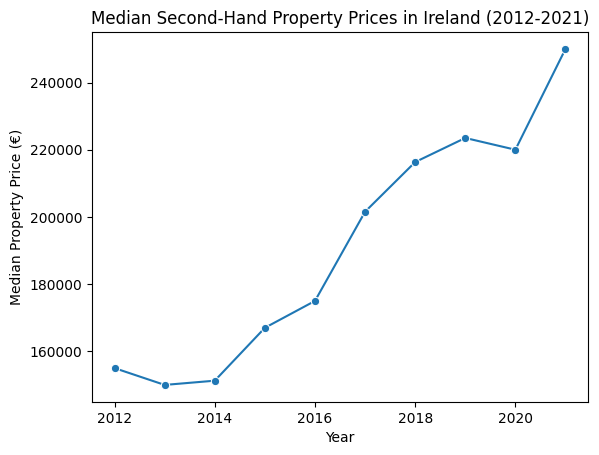

In [106]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(data=yearly_prices, x="Year", y="price_eur", marker="o")

plt.title("Median Second-Hand Property Prices in Ireland (2012-2021)")
plt.xlabel("Year")
plt.ylabel("Median Property Price (€)")
plt.show()

# National house price trends
The graph shows that median second-hand property prices increased considerably in Ireland between 2012 and 2021.

Prices decreased slightly between 2012 and 2013 before increasing steadily from 2014 to 2019. There was a small decrease in 2020, followed by another increase in 2021.

Overall, the median property price rose from approximately €155,000 in 2012 to €250,000 in 2021.

These results are based on the sampled property sales and may also be affected by differences in the properties sold each year.

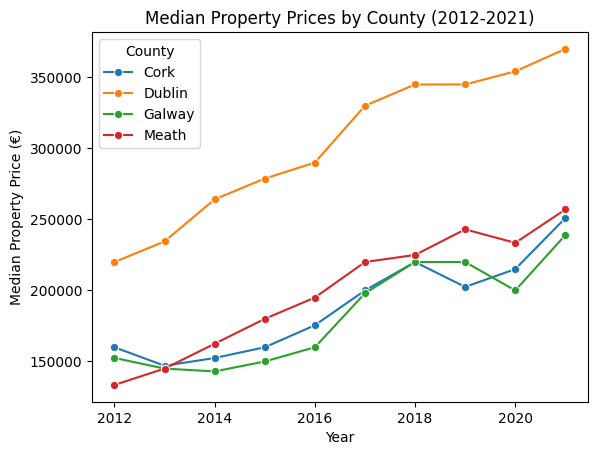

In [108]:
selected_counties = ["Dublin", "Cork", "Meath", "Galway"]

df_selected = df_prices[df_prices["County"].isin(selected_counties)]

sns.lineplot(data=df_selected, x="Year", y="price_eur", hue="County", marker="o")

plt.title("Median Property Prices by County (2012-2021)")
plt.xlabel("Year")
plt.ylabel("Median Property Price (€)")
plt.show()

# County house price comparison
The graph compares median second-hand property prices in Dublin, Cork, Galway and Meath between 2012 and 2021.

Dublin had the highest property prices throughout the period, increasing from approximately €220,000 in 2012 to €370,000 in 2021.

Meath experienced a particularly large increase, starting with the lowest median price of the four counties in 2012 but finishing above Cork and Galway in 2021.

Overall, median property prices increased in all four counties, although there were some fluctuations throughout the period.

In [109]:
yearly_income = df_income.groupby("Year")["Disposable_Income"].mean().reset_index()
yearly_income

,Year,Disposable_Income
0,2012,17174.846154
1,2013,17131.500000
2,2014,17255.538462
3,2015,17874.538462
4,2016,18378.884615
5,2017,19258.538462
6,2018,19768.615385
7,2019,20812.961538
8,2020,22015.461538
9,2021,22626.192308


In [110]:
yearly_prices

,Year,price_eur
0,2012,155000.000
1,2013,150000.000
2,2014,151260.000
3,2015,167000.000
4,2016,175000.000
5,2017,201550.000
6,2018,216327.885
7,2019,223500.000
8,2020,220000.000
9,2021,250000.000


In [111]:
house_price_growth = (yearly_prices["price_eur"].iloc[-1] - yearly_prices["price_eur"].iloc[0]) / yearly_prices["price_eur"].iloc[0] * 100
income_growth = (yearly_income["Disposable_Income"].iloc[-1] - yearly_income["Disposable_Income"].iloc[0]) / yearly_income["Disposable_Income"].iloc[0] * 100
print("House Price Growth:", round(house_price_growth, 2), "%")
print("Disposable Income Growth:", round(income_growth, 2), "%")

House Price Growth: 61.29 %
Disposable Income Growth: 31.74 %


In [112]:
yearly_prices["Price_Index"] = yearly_prices["price_eur"] / yearly_prices["price_eur"].iloc[0] * 100

yearly_income["Income_Index"] = yearly_income["Disposable_Income"] / yearly_income["Disposable_Income"].iloc[0] * 100

In [113]:
df_growth = pd.merge(yearly_prices, yearly_income, on="Year")

df_growth.head()

,Year,price_eur,Price_Index,Disposable_Income,Income_Index
0,2012,155000.0,100.000000,17174.846154,100.000000
1,2013,150000.0,96.774194,17131.500000,99.747618
2,2014,151260.0,97.587097,17255.538462,100.469828
3,2015,167000.0,107.741935,17874.538462,104.073936
4,2016,175000.0,112.903226,18378.884615,107.010476


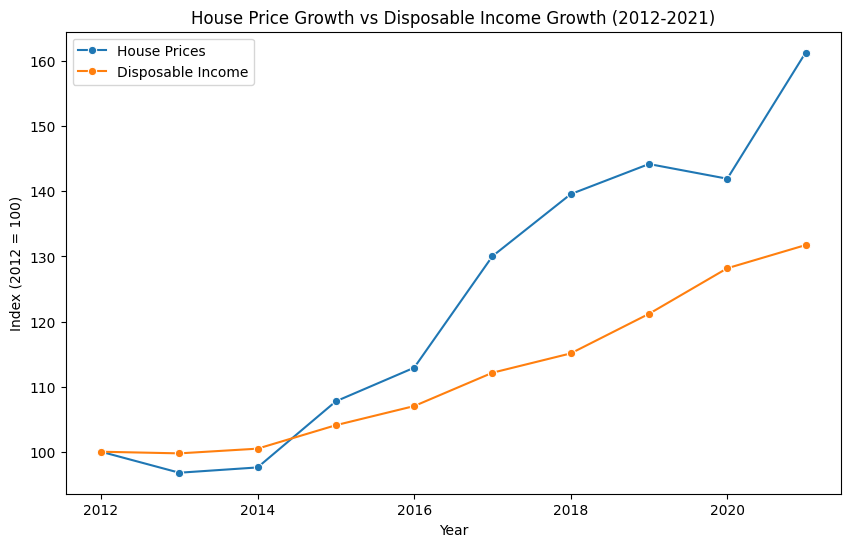

In [114]:
plt.figure(figsize=(10, 6))

sns.lineplot(data=df_growth, x="Year", y="Price_Index", marker="o", label="House Prices")

sns.lineplot(data=df_growth, x="Year", y="Income_Index", marker="o", label="Disposable Income")

plt.title("House Price Growth vs Disposable Income Growth (2012-2021)")
plt.xlabel("Year")
plt.ylabel("Index (2012 = 100)")
plt.legend()
plt.show()

# House price growth vs disposable income growth
The graph compares the percentage growth in median second-hand property prices and disposable income per person in Ireland between 2012 and 2021. Both were set to 100 in 2012 to make the comparison easier to visualise and make comparisons.

Median house prices increased by 61.29%, rising from €155,000 in 2012 to €250,000 in 2021. Over the same period, average disposable income per person across the 26 counties increased by 31.74%, from approx €17,175 to €22,626.

House prices increased particularly quickly between 2016 and 2019, while disposable income increased more gradually. House prices also decreased slightly in 2020 before increasing again in 2021.

Overall, house prices increased by 29.55 percentage points more than disposable income. This suggests that housing may have become less affordable relative to income during this period. However, the results are based on sampled property sales and an unweighted average of county incomes, so they do not provide a complete measure of housing affordability.

In [115]:
prices_2012 = df_prices[df_prices["Year"] == 2012]
prices_2021 = df_prices[df_prices["Year"] == 2021]

df_counties = pd.merge(prices_2012, prices_2021, on="County")

df_counties["Price_Growth"] = (
    (df_counties["price_eur_y"] - df_counties["price_eur_x"])
    / df_counties["price_eur_x"] * 100
)

df_counties.head()

,County,Year_x,price_eur_x,Year_y,price_eur_y,Price_Growth
0,Carlow,2012,92500.0,2021,171000.0,84.864865
1,Cavan,2012,86000.0,2021,162500.0,88.953488
2,Clare,2012,115000.0,2021,186000.0,61.739130
3,Cork,2012,160000.0,2021,251000.0,56.875000
4,Donegal,2012,95000.0,2021,131000.0,37.894737


In [116]:
income_2012 = df_income[df_income["Year"] == 2012]
income_2021 = df_income[df_income["Year"] == 2021]
df_income_growth = pd.merge(income_2012, income_2021, on="County")
df_income_growth["Income_Growth"] = (
    (df_income_growth["Disposable_Income_y"] - df_income_growth["Disposable_Income_x"])
    / df_income_growth["Disposable_Income_x"] * 100
)

In [117]:
df_counties = pd.merge(
    df_counties,
    df_income_growth[["County", "Income_Growth"]],
    on="County"
)

df_counties["Growth_Gap"] = df_counties["Price_Growth"] - df_counties["Income_Growth"]

df_counties[["County", "Price_Growth", "Income_Growth", "Growth_Gap"]]

,County,Price_Growth,Income_Growth,Growth_Gap
0,Carlow,84.864865,30.931730,53.933135
1,Cavan,88.953488,34.581526,54.371962
2,Clare,61.739130,25.944512,35.794619
3,Cork,56.875000,34.250164,22.624836
4,Donegal,37.894737,30.166993,7.727743
5,Dublin,68.181818,40.196570,27.985248
6,Galway,56.721311,36.060922,20.660390
7,Kerry,46.153846,32.214320,13.939526
8,Kildare,86.865672,33.481652,53.384019
9,Kilkenny,75.833333,21.221073,54.612260


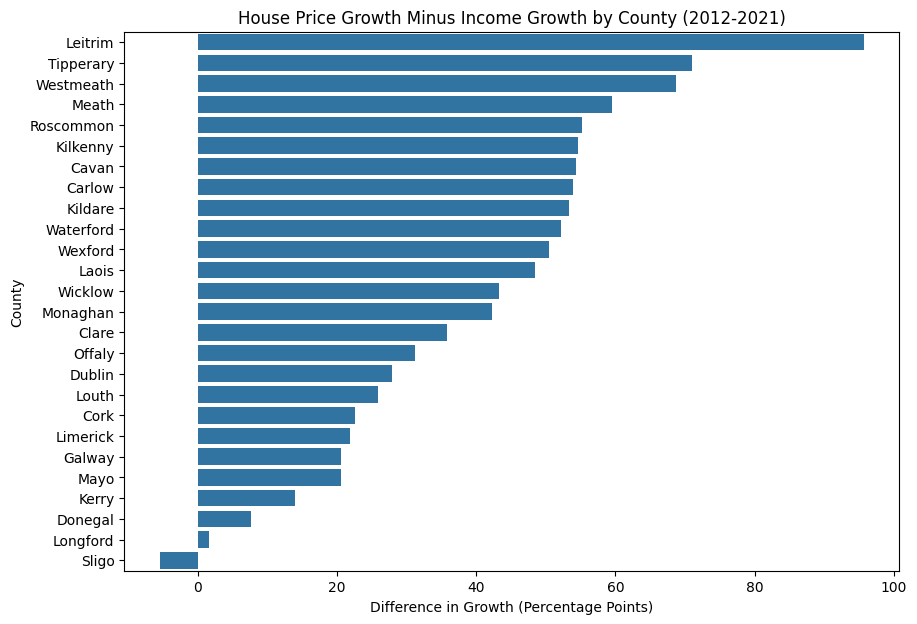

In [118]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=df_counties.sort_values("Growth_Gap", ascending=False),
    x="Growth_Gap",
    y="County"
)

plt.title("House Price Growth Minus Income Growth by County (2012-2021)")
plt.xlabel("Difference in Growth (Percentage Points)")
plt.ylabel("County")
plt.show()

# House price growth compared with income growth just by county
This graph compares the percentage increase in median second-hand property prices with the percentage increase in disposable income per person across all 26 Irish counties between 2012 and 2021.

Leitrim had the largest difference between house-price growth and income growth, followed by Tipperary and Westmeath. Meath also experienced a large difference.
Sligo was the only county where disposable income increased faster than median property prices.

Overall, the results show that house prices increased faster than disposable income in 25 of the 26 counties.

# Conclusion:
## Conclusion

The aim of this project was to investigate how house prices changed across Irish counties between 2012 and 2021 and whether they increased faster than disposable income per person.

Using the Kaggle Property Price Register dataset and income data scraped from the CSO website, I found that median second-hand property prices increased by 61.29%, compared with a 31.74% increase in the unweighted average of county disposable income per person.

The results suggest that property prices increased a lot faster than incomes throughout this period, and particularly after 2016.

There were also differences between counties, with Dublin having consistently higher median property prices than Cork, Galway and Meath.

One limitation is that the analysis uses a random sample of property sales rather than the entire dataset. Some counties have fewer sales than others, which may affect the reliability of the results. Also, property prices can be affected by the types of houses sold each year.

Overall, the findings suggest that purchasing a property may have become more difficult while taking into consideration income between 2012 and 2021, although further information would be needed to fully measure housing affordability.

In [119]:
df_clean.to_csv("cleaned_property_income_data.csv", index=False)